<a href="https://colab.research.google.com/github/Bodazhu/game-review-sentiment-analysis/blob/main/Sentiment_Analysis_VideoGames.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment Analysis – Amazon Video Games Reviews
## Team Project Part B: End-to-End Machine Learning Pipeline

**Dataset:** Amazon Video Games Reviews (2023)  
**Task:** Binary Sentiment Classification (Positive / Negative)  
**Algorithms:** Logistic Regression · SVM · **Random Forest** *(assigned)*  
**Text Representations:** Bag of Words · TF-IDF · N-Grams  
**Framework:** CRISP-DM / Applied Data Science Process Model

---

## Table of Contents
1. [Environment Setup](#1)
2. [Data Collection & Loading](#2)
3. [Exploratory Data Analysis (EDA)](#3)
4. [Data Preparation & Preprocessing](#4)
5. [Text Vectorization (BoW, TF-IDF, N-Grams)](#5)
6. [Model Building – Logistic Regression](#6)
7. [Model Building – SVM](#7)
8. [Model Building – Random Forest (Assigned)](#8)
9. [Hyperparameter Tuning with GridSearchCV](#9)
10. [Model Evaluation & Business Interpretation](#10)
11. [ML Canvas Summary](#11)

---
## 1. Environment Setup <a id='1'></a>

In [ ]:
# Install required packages
!pip install -q nltk scikit-learn pandas numpy matplotlib seaborn wordcloud

In [ ]:
# Core imports
import json
import gzip
import urllib.request
import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# NLP
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

# Sklearn – vectorizers
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Sklearn – models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

# Sklearn – utilities
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve, ConfusionMatrixDisplay
)

# Visualization extras
from wordcloud import WordCloud

# Download NLTK resources
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Plotting style
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

RANDOM_STATE = 42
print('All libraries loaded successfully.')

All libraries loaded successfully.


---
## 2. Data Collection & Loading <a id='2'></a>

**CRISP-DM Phase 3 – Data Collection**

We download the Amazon 2023 Video Games review dataset directly from UCSD McAuley Lab. The raw JSONL format contains fields including `rating`, `text`, and `title`.

In [ ]:
# ─── Download Dataset ──────────────────────────────────────────────────────────
DATA_URL = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Video_Games.jsonl.gz'
LOCAL_PATH = 'Video_Games.jsonl.gz'

if not os.path.exists(LOCAL_PATH):
    print('Downloading dataset (this may take a few minutes)...')
    urllib.request.urlretrieve(DATA_URL, LOCAL_PATH)
    print('Download complete.')
else:
    print('Dataset already downloaded.')

print(f'File size: {os.path.getsize(LOCAL_PATH) / (1024**2):.1f} MB')

Download complete.
File size: 776.5 MB


In [ ]:
# ─── Load Data ────────────────────────────────────────────────────────────────
# We load up to MAX_RECORDS for manageable training time in Colab.
# Increase or remove the cap for a full run.
MAX_RECORDS = 150_000

records = []
with gzip.open(LOCAL_PATH, 'rt', encoding='utf-8') as f:
    for i, line in enumerate(f):
        if i >= MAX_RECORDS:
            break
        try:
            records.append(json.loads(line))
        except json.JSONDecodeError:
            continue

df_raw = pd.DataFrame(records)
print(f'Loaded {len(df_raw):,} records')
print(f'Columns: {list(df_raw.columns)}')
df_raw.head(3)

Loaded 150,000 records
Columns: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4.0,It’s pretty sexual. Not my fav,I’m playing on ps5 and it’s interesting. It’s...,[],B07DJWBYKP,B07DK1H3H5,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1608186804795,0,True
1,5.0,Good. A bit slow,Nostalgic fun. A bit slow. I hope they don’t...,[],B00ZS80PC2,B07SRWRH5D,AGCI7FAH4GL5FI65HYLKWTMFZ2CQ,1587051114941,1,False
2,5.0,... an order for my kids & they have really en...,This was an order for my kids & they have real...,[],B01FEHJYUU,B07MFMFW34,AGXVBIUFLFGMVLATYXHJYL4A5Q7Q,1490877431000,0,True


---
## 3. Exploratory Data Analysis (EDA) <a id='3'></a>

**CRISP-DM Phase 2 – Data Understanding**

In [ ]:
# Basic info
print('=== Dataset Info ===')
df_raw.info()
print('\n=== Null Values ===')
print(df_raw.isnull().sum())

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   rating             150000 non-null  float64
 1   title              150000 non-null  object 
 2   text               150000 non-null  object 
 3   images             150000 non-null  object 
 4   asin               150000 non-null  object 
 5   parent_asin        150000 non-null  object 
 6   user_id            150000 non-null  object 
 7   timestamp          150000 non-null  int64  
 8   helpful_vote       150000 non-null  int64  
 9   verified_purchase  150000 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(6)
memory usage: 10.4+ MB

=== Null Values ===
rating               0
title                0
text                 0
images               0
asin                 0
parent_asin          0
user_id              0
timestamp            0
hel

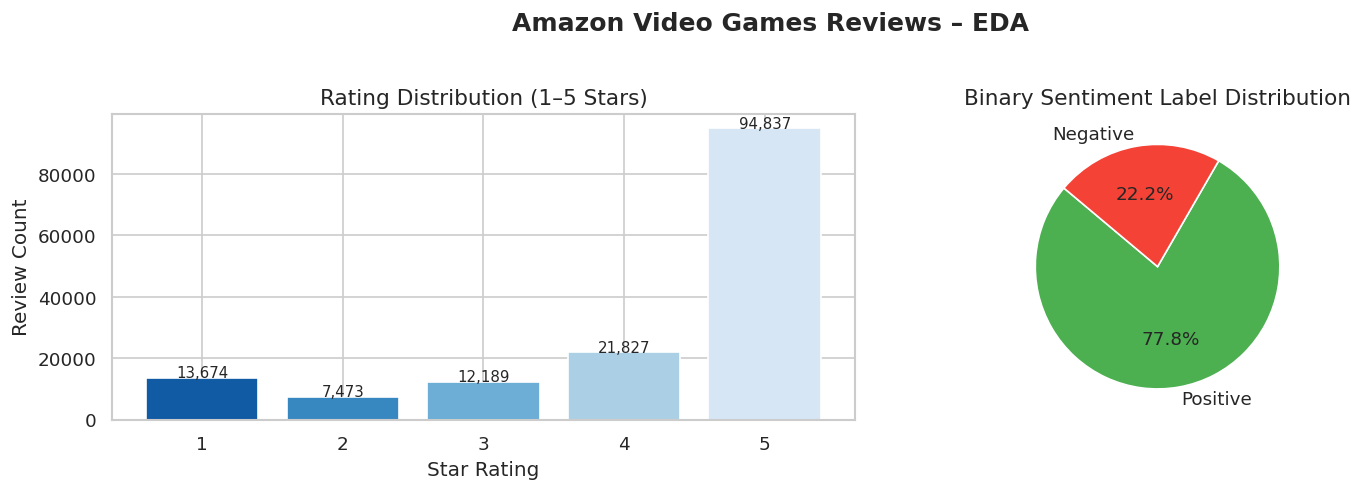

sentiment
Positive    116664
Negative     33336
Name: count, dtype: int64


In [ ]:
# ─── Rating Distribution ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

rating_counts = df_raw['rating'].value_counts().sort_index()
axes[0].bar(rating_counts.index, rating_counts.values, color=sns.color_palette('Blues_r', 5))
axes[0].set_title('Rating Distribution (1–5 Stars)', fontsize=13)
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Review Count')
for i, v in enumerate(rating_counts.values):
    axes[0].text(rating_counts.index[i], v + 200, f'{v:,}', ha='center', fontsize=9)

# Sentiment label distribution (positive = rating >= 4)
df_raw['sentiment'] = df_raw['rating'].apply(lambda x: 'Positive' if x >= 4 else 'Negative')
sent_counts = df_raw['sentiment'].value_counts()
axes[1].pie(sent_counts.values, labels=sent_counts.index,
            autopct='%1.1f%%', colors=['#4CAF50', '#F44336'],
            startangle=140, textprops={'fontsize': 11})
axes[1].set_title('Binary Sentiment Label Distribution', fontsize=13)

plt.suptitle('Amazon Video Games Reviews – EDA', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print(sent_counts)

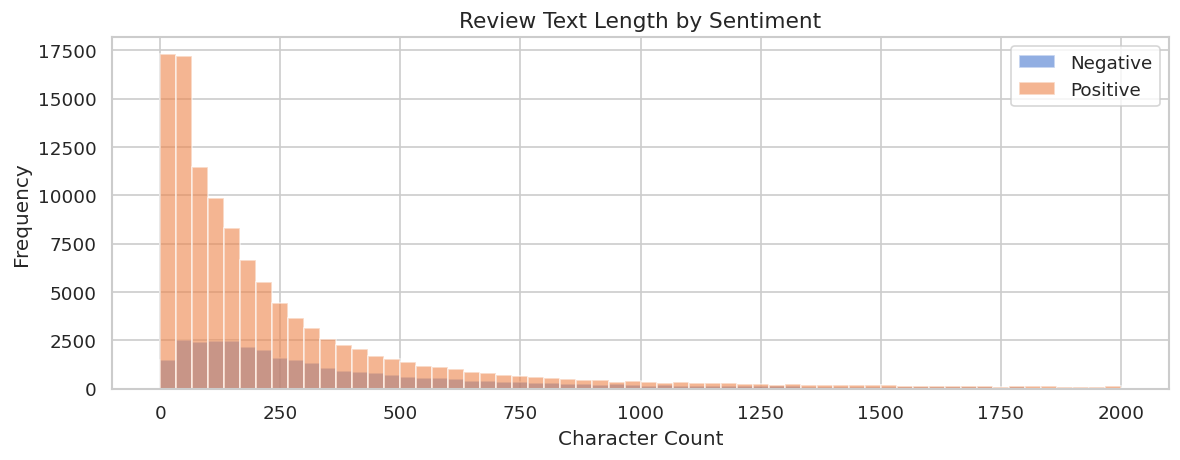

              count   mean    std  min    25%    50%    75%      max
sentiment                                                           
Negative    33336.0  505.4  816.4  3.0  127.0  259.0  549.0  20842.0
Positive   116664.0  333.9  663.2  3.0   55.0  143.0  334.0  27045.0


In [ ]:
# ─── Review Text Length Analysis ───────────────────────────────────────────────
df_raw['review_text'] = df_raw['text'].fillna('') + ' ' + df_raw['title'].fillna('')
df_raw['text_length'] = df_raw['review_text'].apply(len)

fig, ax = plt.subplots(figsize=(10, 4))
df_raw.groupby('sentiment')['text_length'].plot.hist(
    bins=60, alpha=0.6, ax=ax, legend=True, range=(0, 2000)
)
ax.set_title('Review Text Length by Sentiment', fontsize=13)
ax.set_xlabel('Character Count')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

print(df_raw.groupby('sentiment')['text_length'].describe().round(1))

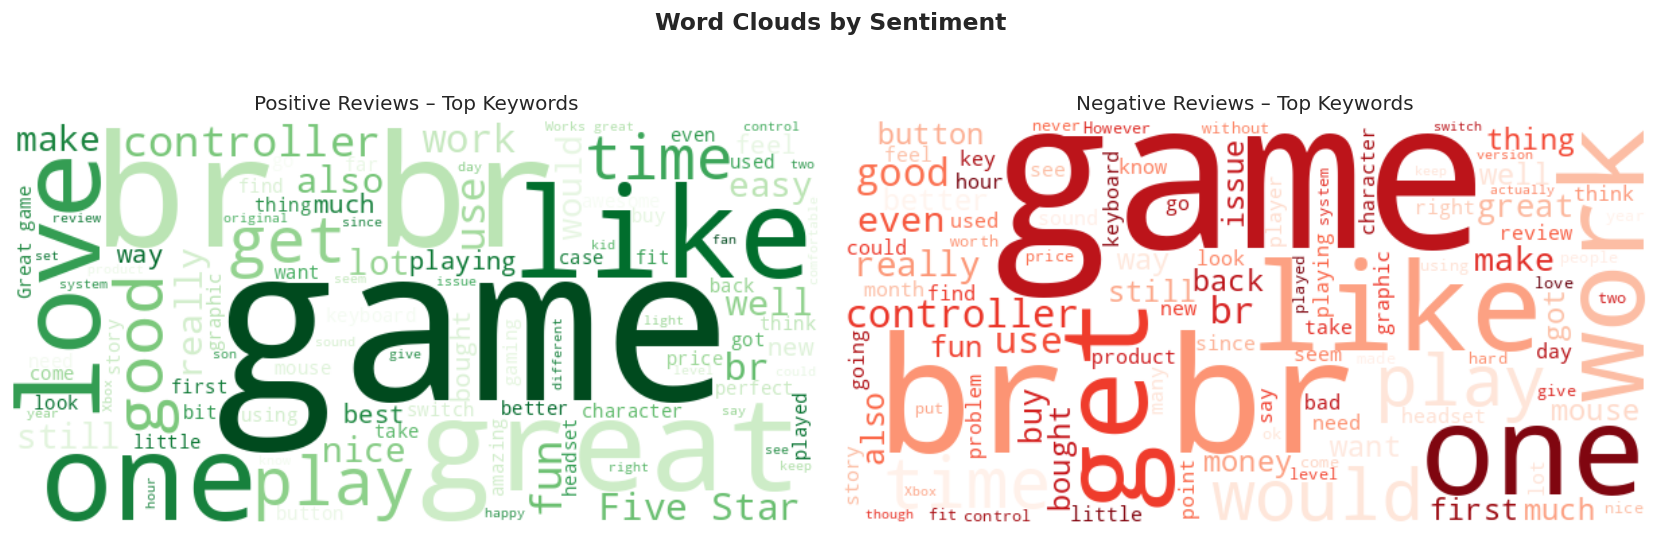

In [ ]:
# ─── Word Cloud ────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, label, cmap in zip(axes, ['Positive', 'Negative'], ['Greens', 'Reds']):
    text_blob = ' '.join(df_raw[df_raw['sentiment'] == label]['review_text'].sample(
        min(5000, len(df_raw[df_raw['sentiment'] == label])), random_state=42))
    wc = WordCloud(width=600, height=300, background_color='white',
                   colormap=cmap, max_words=100, stopwords=set(stopwords.words('english')))
    wc.generate(text_blob)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'{label} Reviews – Top Keywords', fontsize=12)

plt.suptitle('Word Clouds by Sentiment', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 4. Data Preparation & Preprocessing <a id='4'></a>

**CRISP-DM Phase 3 – Data Preparation**

Steps:
- Drop rows with empty review text
- Lowercase, remove punctuation/numbers/special characters
- Remove stopwords, apply stemming
- Balance classes via undersampling (avoids class imbalance bias)
- Train/test split (80/20)

In [ ]:
import re

stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def clean_text(text: str) -> str:
    """Lowercase → remove non-alpha → tokenize → remove stopwords → stem."""
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)  # keep only letters
    tokens = text.split()
    tokens = [stemmer.stem(t) for t in tokens if t not in stop_words and len(t) > 2]
    return ' '.join(tokens)

# Drop rows with no text
df = df_raw[df_raw['review_text'].str.strip() != ''].copy()
df['clean_text'] = df['review_text'].apply(clean_text)
df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)

print(f'Records after cleaning: {len(df):,}')
print('\nSample cleaned text:')
print(df[['review_text', 'clean_text', 'sentiment']].sample(3, random_state=42).to_string())

Records after cleaning: 149,785

Sample cleaned text:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                review_text                                                                                                                                                                                                                                                                                                                          clean_text se

In [ ]:
# ─── Class Balancing (undersample majority) ────────────────────────────────────
n_min = df['sentiment'].value_counts().min()
SAMPLE_CAP = min(n_min, 40_000)  # cap per class for Colab speed

df_balanced = (
    df.groupby('sentiment', group_keys=False)
      .apply(lambda x: x.sample(SAMPLE_CAP, random_state=RANDOM_STATE))
      .reset_index(drop=True)
)

print(f'Balanced dataset size: {len(df_balanced):,}')
print(df_balanced['sentiment'].value_counts())

# Encode labels: Positive=1, Negative=0
df_balanced['label'] = (df_balanced['sentiment'] == 'Positive').astype(int)

X = df_balanced['clean_text']
y = df_balanced['label']

# Train / Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'\nTrain size: {len(X_train):,} | Test size: {len(X_test):,}')

Balanced dataset size: 66,588
sentiment
Negative    33294
Positive    33294
Name: count, dtype: int64

Train size: 53,270 | Test size: 13,318


---
## 5. Text Vectorization: Bag of Words, TF-IDF, N-Grams <a id='5'></a>

Three vectorization strategies are applied:

| Technique | Description |
|-----------|-------------|
| **Bag of Words (BoW)** | Raw word counts, unigrams |
| **TF-IDF** | Term frequency × inverse document frequency, unigrams |
| **N-Grams (TF-IDF)** | TF-IDF with bigrams + trigrams to capture phrases |

In [ ]:
# Vectorizer definitions
vectorizers = {
    'BoW':    CountVectorizer(max_features=20_000, min_df=2),
    'TF-IDF': TfidfVectorizer(max_features=20_000, min_df=2, sublinear_tf=True),
    'NGrams': TfidfVectorizer(max_features=20_000, min_df=2, ngram_range=(1, 3), sublinear_tf=True),
}

# Fit & transform
X_vecs = {}
for name, vec in vectorizers.items():
    X_train_v = vec.fit_transform(X_train)
    X_test_v  = vec.transform(X_test)
    X_vecs[name] = (X_train_v, X_test_v)
    print(f'{name:8s} → train shape: {X_train_v.shape}, test shape: {X_test_v.shape}')

print('\n Vectorization complete.')

BoW      → train shape: (53270, 15024), test shape: (13318, 15024)
TF-IDF   → train shape: (53270, 15024), test shape: (13318, 15024)
NGrams   → train shape: (53270, 20000), test shape: (13318, 20000)

Vectorization complete.


---
## 6. Model Building – Logistic Regression <a id='6'></a>

In [ ]:
# ─── Helper: train & score ─────────────────────────────────────────────────────
def train_evaluate(model, X_tr, X_te, y_tr, y_te, model_name='', vec_name=''):
    """Train model, return dict of metrics."""
    t0 = time.time()
    model.fit(X_tr, y_tr)
    elapsed = time.time() - t0
    y_pred = model.predict(X_te)

    # ROC-AUC (use predict_proba if available, else decision_function)
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_te)[:, 1]
    else:
        y_score = model.decision_function(X_te)

    auc = roc_auc_score(y_te, y_score)
    report = classification_report(y_te, y_pred, output_dict=True)

    result = {
        'model': model_name,
        'vectorizer': vec_name,
        'accuracy': accuracy_score(y_te, y_pred),
        'precision': report['weighted avg']['precision'],
        'recall':    report['weighted avg']['recall'],
        'f1':        report['weighted avg']['f1-score'],
        'roc_auc':   auc,
        'train_sec': elapsed,
        'y_pred':    y_pred,
        'y_score':   y_score,
    }
    return result

all_results = []
print('Helper function defined')

Helper function defined 


In [ ]:
print('=== Logistic Regression ===')
lr_results = []

for vec_name, (X_tr, X_te) in X_vecs.items():
    lr = LogisticRegression(max_iter=1000, C=1.0, random_state=RANDOM_STATE, n_jobs=-1)
    r = train_evaluate(lr, X_tr, X_te, y_train, y_test, 'Logistic Regression', vec_name)
    lr_results.append(r)
    all_results.append(r)
    print(f'  [{vec_name}] Acc={r["accuracy"]:.4f} | F1={r["f1"]:.4f} | AUC={r["roc_auc"]:.4f} | {r["train_sec"]:.1f}s')

=== Logistic Regression ===
  [BoW] Acc=0.8636 | F1=0.8636 | AUC=0.9217 | 5.4s
  [TF-IDF] Acc=0.8772 | F1=0.8772 | AUC=0.9475 | 1.6s
  [NGrams] Acc=0.8856 | F1=0.8856 | AUC=0.9538 | 1.5s


---
## 7. Model Building – SVM (LinearSVC) <a id='7'></a>

In [ ]:
print('=== SVM (LinearSVC) ===')
svm_results = []

for vec_name, (X_tr, X_te) in X_vecs.items():
    svm = LinearSVC(C=1.0, max_iter=2000, random_state=RANDOM_STATE)
    r = train_evaluate(svm, X_tr, X_te, y_train, y_test, 'SVM', vec_name)
    svm_results.append(r)
    all_results.append(r)
    print(f'  [{vec_name}] Acc={r["accuracy"]:.4f} | F1={r["f1"]:.4f} | AUC={r["roc_auc"]:.4f} | {r["train_sec"]:.1f}s')

=== SVM (LinearSVC) ===
  [BoW] Acc=0.8548 | F1=0.8548 | AUC=0.9041 | 115.4s
  [TF-IDF] Acc=0.8698 | F1=0.8698 | AUC=0.9434 | 1.4s
  [NGrams] Acc=0.8776 | F1=0.8776 | AUC=0.9475 | 1.6s


---
## 8. Model Building – Random Forest (Assigned) <a id='8'></a>

> **This is the assigned algorithm for our team.**

Random Forest is an ensemble method that builds many decision trees on random feature subsets and aggregates their votes. It is robust to overfitting and provides feature importance scores — valuable for understanding *which words* most strongly drive sentiment predictions.

In [ ]:
print('=== Random Forest ===')
rf_results = []

for vec_name, (X_tr, X_te) in X_vecs.items():
    rf = RandomForestClassifier(
        n_estimators=200,
        max_depth=30,
        min_samples_split=5,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
    r = train_evaluate(rf, X_tr, X_te, y_train, y_test, 'Random Forest', vec_name)
    r['model_obj'] = rf  # save for feature importance
    rf_results.append(r)
    all_results.append(r)
    print(f'  [{vec_name}] Acc={r["accuracy"]:.4f} | F1={r["f1"]:.4f} | AUC={r["roc_auc"]:.4f} | {r["train_sec"]:.1f}s')

=== Random Forest ===
  [BoW] Acc=0.8166 | F1=0.8166 | AUC=0.9024 | 29.2s
  [TF-IDF] Acc=0.8085 | F1=0.8084 | AUC=0.8958 | 30.5s
  [NGrams] Acc=0.8200 | F1=0.8200 | AUC=0.9068 | 30.9s


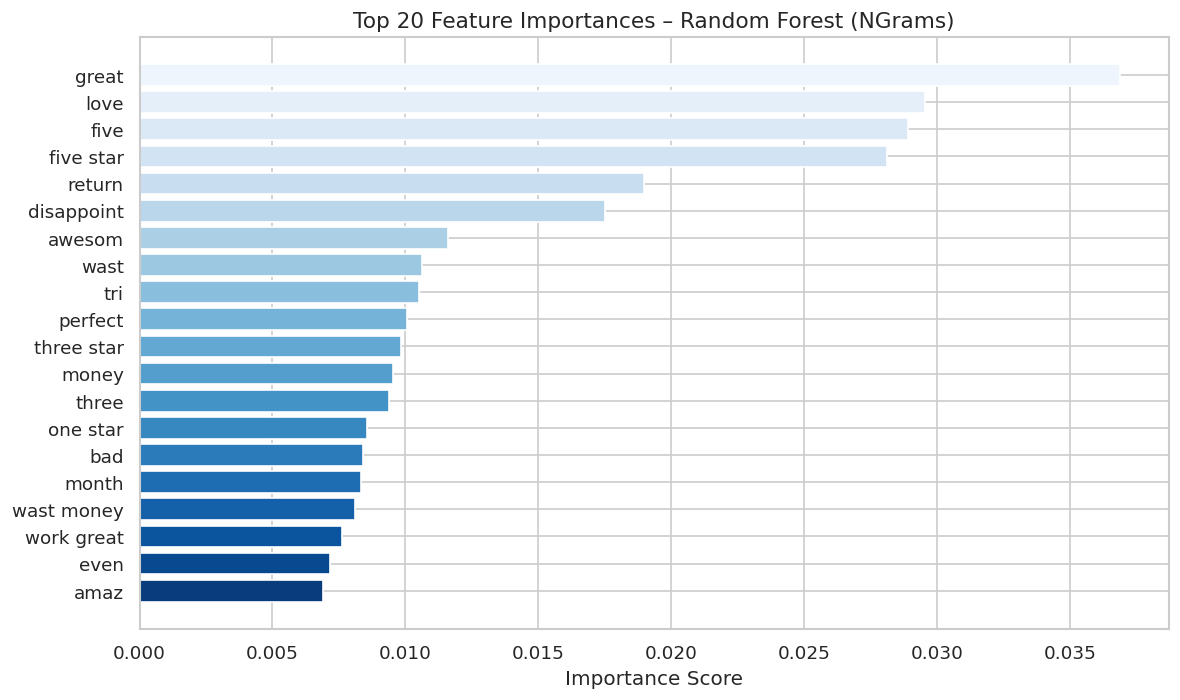

In [ ]:
# ─── Feature Importance (Best RF = TF-IDF) ────────────────────────────────────
best_rf_result = max(rf_results, key=lambda x: x['f1'])
best_vec_name  = best_rf_result['vectorizer']
best_rf_model  = best_rf_result['model_obj']
best_vec       = vectorizers[best_vec_name]

importances = best_rf_model.feature_importances_
feature_names = best_vec.get_feature_names_out()

top_n = 20
top_idx = np.argsort(importances)[::-1][:top_n]
top_features = feature_names[top_idx]
top_importances = importances[top_idx]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_features[::-1], top_importances[::-1], color=sns.color_palette('Blues_r', top_n))
ax.set_title(f'Top {top_n} Feature Importances – Random Forest ({best_vec_name})', fontsize=13)
ax.set_xlabel('Importance Score')
plt.tight_layout()
plt.show()

---
## 9. Hyperparameter Tuning with GridSearchCV <a id='9'></a>

We tune the best-performing vectorizer + Random Forest combination.

In [ ]:
print('Running GridSearchCV for Random Forest (TF-IDF) – this may take several minutes...')

# Use TF-IDF features (generally best for RF)
X_tr_tfidf, X_te_tfidf = X_vecs['TF-IDF']

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [20, 30, None],
    'min_samples_split': [2, 5],
}

grid_rf = GridSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
    param_grid,
    cv=3,
    scoring='f1_weighted',
    verbose=1,
    n_jobs=-1
)
grid_rf.fit(X_tr_tfidf, y_train)

print(f'\n Best params: {grid_rf.best_params_}')
print(f'Best CV F1 (weighted): {grid_rf.best_score_:.4f}')

⚙️  Running GridSearchCV for Random Forest (TF-IDF) – this may take several minutes...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Best params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 200}
Best CV F1 (weighted): 0.8391


In [ ]:
# Evaluate tuned model
best_rf_tuned = grid_rf.best_estimator_
y_pred_tuned  = best_rf_tuned.predict(X_te_tfidf)

if hasattr(best_rf_tuned, 'predict_proba'):
    y_score_tuned = best_rf_tuned.predict_proba(X_te_tfidf)[:, 1]

print('=== Tuned Random Forest – Classification Report ===')
print(classification_report(y_test, y_pred_tuned, target_names=['Negative', 'Positive']))
print(f'ROC-AUC: {roc_auc_score(y_test, y_score_tuned):.4f}')

=== Tuned Random Forest – Classification Report ===
              precision    recall  f1-score   support

    Negative       0.82      0.91      0.86      6659
    Positive       0.89      0.80      0.85      6659

    accuracy                           0.85     13318
   macro avg       0.86      0.85      0.85     13318
weighted avg       0.86      0.85      0.85     13318

ROC-AUC: 0.9372


---
## 10. Model Evaluation & Business Interpretation <a id='10'></a>

**CRISP-DM Phase 5 – Evaluation**

In [ ]:
# ─── Summary Table ─────────────────────────────────────────────────────────────
summary_df = pd.DataFrame([{
    'Model':      r['model'],
    'Vectorizer': r['vectorizer'],
    'Accuracy':   round(r['accuracy'], 4),
    'Precision':  round(r['precision'], 4),
    'Recall':     round(r['recall'], 4),
    'F1-Score':   round(r['f1'], 4),
    'ROC-AUC':    round(r['roc_auc'], 4),
    'Train (s)':  round(r['train_sec'], 1),
} for r in all_results])

summary_df = summary_df.sort_values('F1-Score', ascending=False).reset_index(drop=True)
print('=== Model Performance Summary ===')
print(summary_df.to_string(index=False))

=== Model Performance Summary ===
              Model Vectorizer  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Train (s)
Logistic Regression     NGrams    0.8856     0.8857  0.8856    0.8856   0.9538        1.5
                SVM     NGrams    0.8776     0.8776  0.8776    0.8776   0.9475        1.6
Logistic Regression     TF-IDF    0.8772     0.8774  0.8772    0.8772   0.9475        1.6
                SVM     TF-IDF    0.8698     0.8698  0.8698    0.8698   0.9434        1.4
Logistic Regression        BoW    0.8636     0.8637  0.8636    0.8636   0.9217        5.4
                SVM        BoW    0.8548     0.8549  0.8548    0.8548   0.9041      115.4
      Random Forest     NGrams    0.8200     0.8202  0.8200    0.8200   0.9068       30.9
      Random Forest        BoW    0.8166     0.8166  0.8166    0.8166   0.9024       29.2
      Random Forest     TF-IDF    0.8085     0.8087  0.8085    0.8084   0.8958       30.5


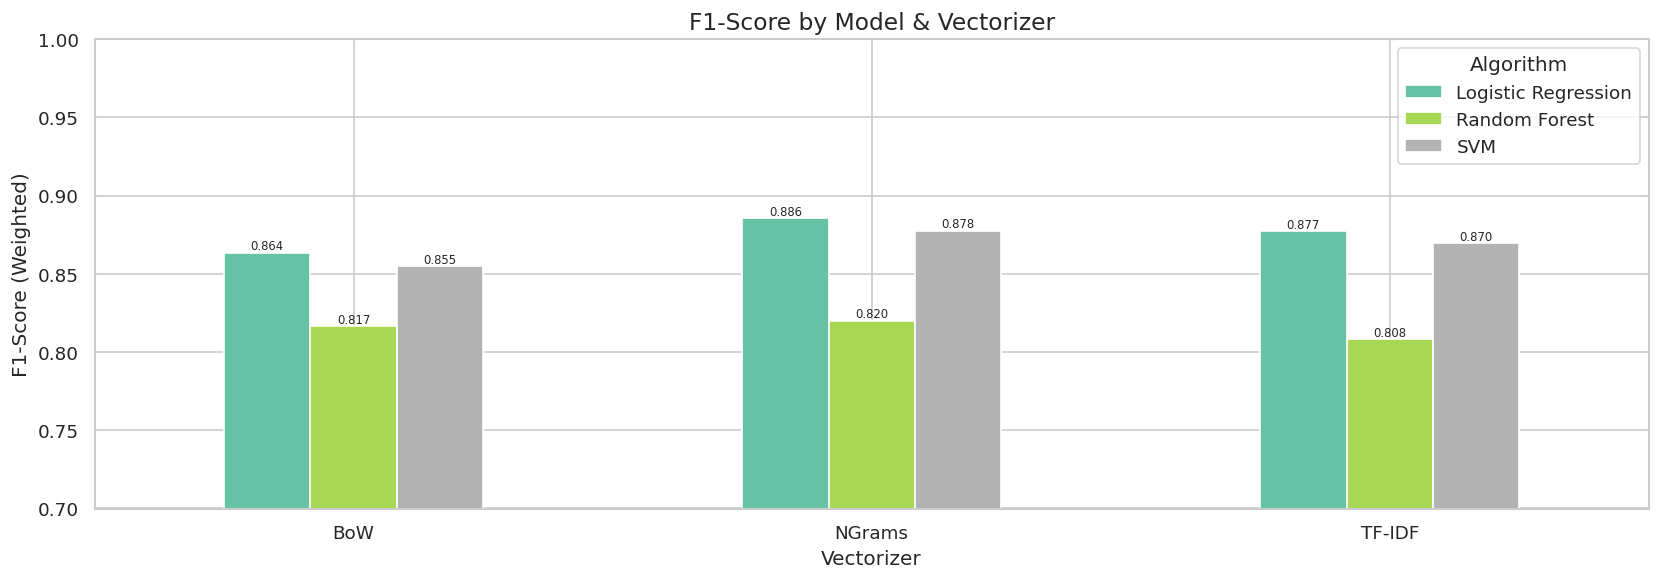

In [ ]:
# ─── Grouped Bar Chart ─────────────────────────────────────────────────────────
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']

fig, ax = plt.subplots(figsize=(14, 5))
pivot = summary_df.pivot_table(index='Vectorizer', columns='Model', values='F1-Score')
pivot.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='white')
ax.set_title('F1-Score by Model & Vectorizer', fontsize=14)
ax.set_xlabel('Vectorizer')
ax.set_ylabel('F1-Score (Weighted)')
ax.set_ylim(0.7, 1.0)
ax.legend(title='Algorithm')
ax.tick_params(axis='x', rotation=0)
for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}', (p.get_x() + p.get_width() / 2, p.get_height() + 0.002),
                ha='center', fontsize=7)
plt.tight_layout()
plt.show()

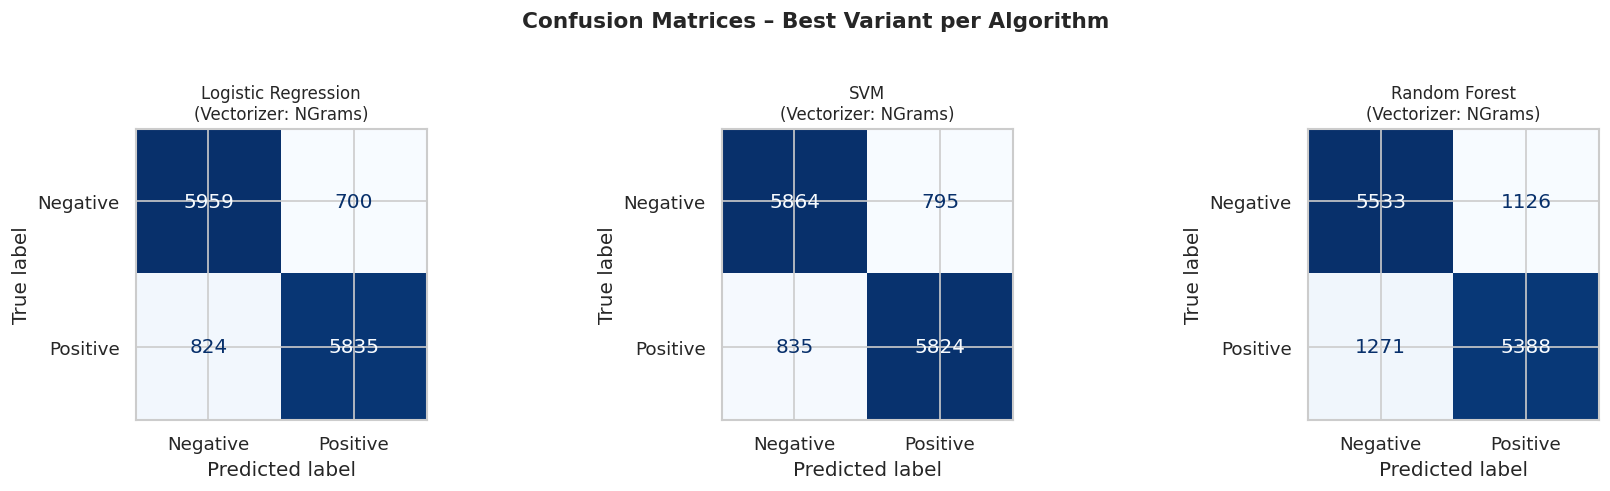

In [ ]:
# ─── Confusion Matrices (Best of each model) ──────────────────────────────────
best_per_model = {}
for model_name in ['Logistic Regression', 'SVM', 'Random Forest']:
    candidates = [r for r in all_results if r['model'] == model_name]
    best_per_model[model_name] = max(candidates, key=lambda x: x['f1'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (mname, r) in zip(axes, best_per_model.items()):
    cm = confusion_matrix(y_test, r['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Negative', 'Positive'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{mname}\n(Vectorizer: {r["vectorizer"]})', fontsize=10)

plt.suptitle('Confusion Matrices – Best Variant per Algorithm', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

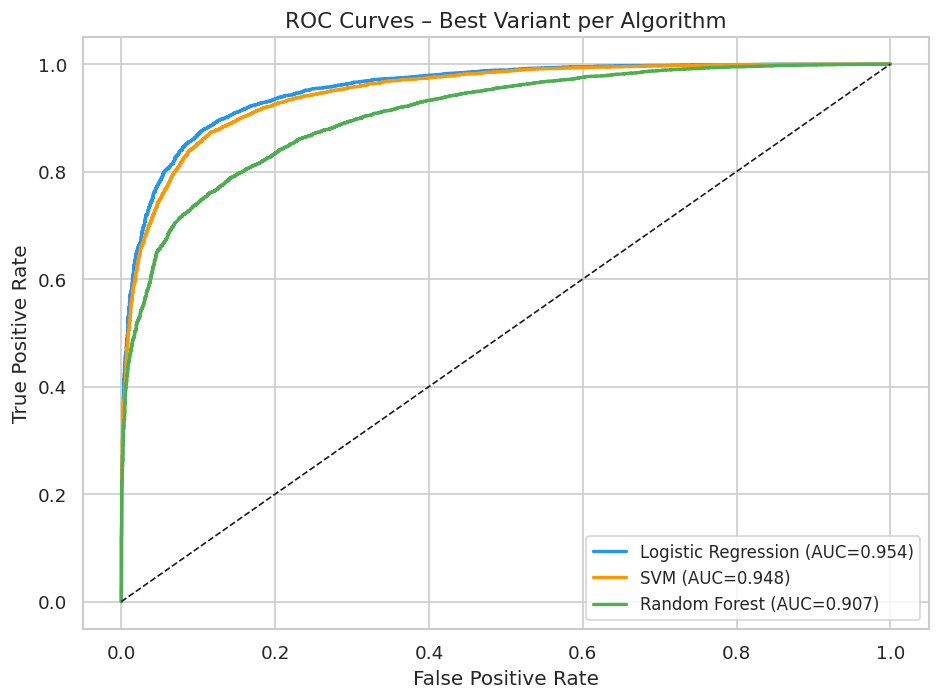

In [ ]:
# ─── ROC Curves ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
colors = {'Logistic Regression': '#2196F3', 'SVM': '#FF9800', 'Random Forest': '#4CAF50'}

for mname, r in best_per_model.items():
    fpr, tpr, _ = roc_curve(y_test, r['y_score'])
    ax.plot(fpr, tpr, label=f"{mname} (AUC={r['roc_auc']:.3f})",
            color=colors[mname], lw=2)

ax.plot([0, 1], [0, 1], 'k--', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves – Best Variant per Algorithm', fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
# ─── Business Impact: False Negatives vs False Positives ──────────────────────
print('=== Business Impact Analysis: FN vs FP ===')
print()
print('Label mapping: Positive=1 (satisfied customer), Negative=0 (dissatisfied customer)')
print()

for mname, r in best_per_model.items():
    cm = confusion_matrix(y_test, r['y_pred'])
    tn, fp, fn, tp = cm.ravel()
    print(f'--- {mname} ({r["vectorizer"]}) ---')
    print(f'  True Positives  (TP): {tp:5,}  → Correctly predicted positive: no action needed')
    print(f'  True Negatives  (TN): {tn:5,}  → Correctly predicted negative: flag for intervention')
    print(f'  False Positives (FP): {fp:5,}  → Negative review wrongly predicted Positive')
    print(f'                         ⚠️  Business Risk: Missed unhappy customers → churn risk')
    print(f'  False Negatives (FN): {fn:5,}  → Positive review wrongly predicted Negative')
    print(f'                         ⚠️  Business Risk: Wasted resources on satisfied customers')
    print()

print(' Key Insight:')
print('   For the product marketing team, FALSE POSITIVES (FP) are costlier:')
print('   Missing a genuinely negative review means failing to act on customer dissatisfaction,')
print('   risking brand damage, lower ratings, and lost sales.')
print('   → Prioritize HIGH RECALL for the Negative class in production deployment.')

=== Business Impact Analysis: FN vs FP ===

Label mapping: Positive=1 (satisfied customer), Negative=0 (dissatisfied customer)

--- Logistic Regression (NGrams) ---
  True Positives  (TP): 5,835  → Correctly predicted positive: no action needed
  True Negatives  (TN): 5,959  → Correctly predicted negative: flag for intervention
  False Positives (FP):   700  → Negative review wrongly predicted Positive
                         ⚠️  Business Risk: Missed unhappy customers → churn risk
  False Negatives (FN):   824  → Positive review wrongly predicted Negative
                         ⚠️  Business Risk: Wasted resources on satisfied customers

--- SVM (NGrams) ---
  True Positives  (TP): 5,824  → Correctly predicted positive: no action needed
  True Negatives  (TN): 5,864  → Correctly predicted negative: flag for intervention
  False Positives (FP):   795  → Negative review wrongly predicted Positive
                         ⚠️  Business Risk: Missed unhappy customers → churn risk
  False

---
## 11. ML Canvas Summary <a id='11'></a>

| Section | Details |
|---------|----------|
| **GOAL – What** | Predict sentiment (positive/negative) of Amazon Video Game reviews |
| **GOAL – Why** | Help the product marketing team identify dissatisfied customers and prioritize product improvements |
| **GOAL – Who** | Product managers, marketing analysts, customer success teams |
| **ML Task (Predict)** | Binary text classification (Positive=1, Negative=0) |
| **Decisions** | Trigger outreach/response workflows for predicted-negative reviews |
| **Data Sources (Learn)** | Amazon 2023 review dataset – `rating`, `text`, `title` fields |
| **Features** | TF-IDF / BoW / N-gram vectors from cleaned review text |
| **Models Built** | Logistic Regression, SVM, **Random Forest** |
| **Offline Evaluation** | Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrix |
| **Live Evaluation** | Monitor prediction distribution drift; retrain quarterly |
| **Business Outcome** | Reduce response time to negative reviews → improve customer satisfaction score |

---

### Part B Checklist
- [x] 1. ML Canvas completed
- [x] 2. Three text representations applied: **BoW, TF-IDF, N-Grams**
- [x] 3. Three classification algorithms: **Logistic Regression, SVM, Random Forest**
- [x] 4. GridSearchCV hyperparameter tuning applied (Random Forest)
- [x] 5. Model evaluation: confusion matrix, precision, recall, ROC-AUC, business interpretation